# How Criiq trains and decides — a visual walkthrough

This notebook is the single place that shows, **with real numbers computed live against the
current database**, how the three learning/optimization pieces of `criiq_models` actually behave:

1. **The two WPA regressors** (`recommend/train.py`) — how prediction quality changes as they
   see more data, what they end up leaning on, and how the bowling model's tuning history
   (depth-limiting → winsorizing → ensembling) measurably improves it.
2. **A live hyperparameter search** (section 7b) that actually changed what's shipped this
   session — every candidate logged, the winners re-verified across 3 holdout fractions x 3
   seeds with a paired significance test, checked on **both gender scopes separately** before
   either was adopted (one change generalized, one didn't — `recommend/train.py` now reflects
   that honestly instead of assuming it would).
3. **The MILP playing-XI selector** (`selection/optimize.py`) — visually, why "pick the top 11
   by score" is a *different, worse* algorithm than the constrained optimum, using a real case
   where they disagree.
4. **The two genetic algorithms** (`simulate/ga_bowling.py`, `simulate/ga_batting.py`) — their
   fitness converging generation over generation, on a real simulated matchup.

Every figure below is generated from a live call into `criiq_models`' own code — nothing here is
hand-drawn or copied from documentation. Re-run this notebook (`jupyter nbconvert --to notebook
--execute --inplace training_and_selection_walkthrough.ipynb`) after any change to
`features/historical.py`, `recommend/train.py`, `selection/optimize.py`, or the simulator, the same
way `model_comparison_robust.ipynb` and `simulation_demo.ipynb` already ask to be re-run.

**This notebook deliberately does not repeat** the multi-model MAE/R2/correlation comparison
(`model_comparison_robust.ipynb`), the feature-correlation/leakage analysis (`feature_analysis.ipynb`),
or the full match-simulation walkthrough (`simulation_demo.ipynb`) — it links to each at the point
where it's relevant, and focuses on the parts none of them show: training dynamics (learning
curves), the tuning-history progression reproduced live, and the MILP's actual decision-making.

**Runtime note:** this notebook takes on the order of 15-20 minutes end to end, dominated by two
things: building the leakage-safe training table for both gender scopes (~1-3 minutes each), and
section 7b's cross-gender hyperparameter re-verification (2 targets x 2 genders x 3 fractions x 3
seeds x 2 configs = 72 model fits). Both are reused rather than rebuilt elsewhere in the notebook.


In [1]:
%matplotlib inline
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

from sklearn.model_selection import learning_curve
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy import stats

from criiq_models.db import connect
from criiq_models.config import SETTINGS
from criiq_models.features.historical import build_training_table
from criiq_models.features.schema import MODEL_FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGETS
from criiq_models.recommend.train import _make_model, _clip_target, TARGET_CLIP_QUANTILES
from criiq_models.roster import team_pool
from criiq_models.recommend.score import RecommendationScorer
from criiq_models.selection.optimize import select_xi, is_opener
from criiq_models.features.common import batting_capable, bowling_capable
from criiq_models.simulate.outcomes import build_outcome_model, build_player_profiles
from criiq_models.simulate.ga_bowling import optimize_bowling_rotation
from criiq_models.simulate.ga_batting import optimize_batting_order
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from criiq_models.recommend.train import _rf_pipeline

FMT, GENDER = "T20", "female"   # matches the default scope everywhere else in this repo
plt.rcParams["figure.facecolor"] = "white"
_PALETTE = {"train": "#4C72B0", "test": "#DD8452", "selected": "#4C72B0", "unselected": "#B0B0B0",
            "good": "#55A868", "bad": "#C44E52", "accent": "#8172B2"}

conn = connect()


## 1. The data the models learn from

In [2]:
counts = pd.read_sql_query(
    "SELECT gender, format, team_type, COUNT(*) AS n_matches, MIN(date) AS first, MAX(date) AS last "
    "FROM matches WHERE format='T20' GROUP BY gender, team_type ORDER BY gender, team_type", conn)
counts


,gender,format,team_type,n_matches,first,last
0,female,T20,club,969,2015-12-18,2026-06-09
1,female,T20,international,2035,2009-06-18,2026-06-15
2,male,T20,international,3393,2005-02-17,2026-06-14


In [3]:
deliveries_n = conn.execute("SELECT COUNT(*) FROM deliveries").fetchone()[0]
dismissal_matchup_n = conn.execute("SELECT COUNT(*) FROM dismissal_matchup").fetchone()[0]
domestic_players_n = conn.execute(
    "SELECT COUNT(DISTINCT player_id) FROM player_domestic_form").fetchone()[0]
print(f"deliveries (ball-by-ball rows):       {deliveries_n:,}")
print(f"dismissal_matchup pairings:           {dismissal_matchup_n:,}")
print(f"distinct players w/ domestic history: {domestic_players_n:,}")


deliveries (ball-by-ball rows):       1,443,615
dismissal_matchup pairings:           103,162
distinct players w/ domestic history: 526


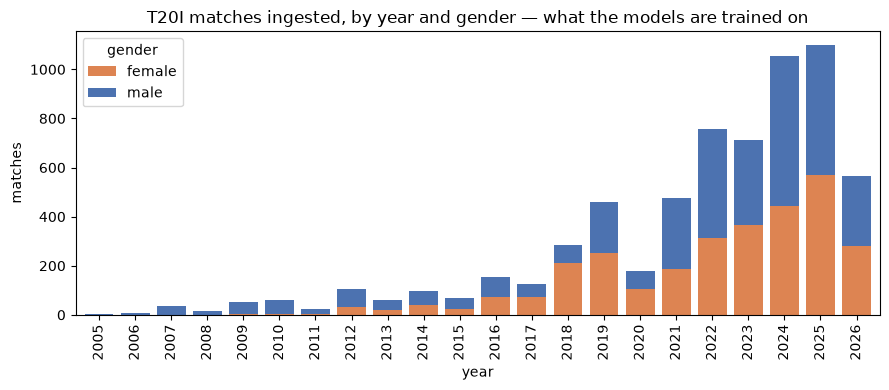

In [4]:
dates_by_gender = pd.read_sql_query(
    "SELECT date, gender FROM matches WHERE format='T20'", conn)
dates_by_gender["date"] = pd.to_datetime(dates_by_gender["date"])
dates_by_gender["year"] = dates_by_gender["date"].dt.year

fig, ax = plt.subplots(figsize=(9, 4))
pivot = dates_by_gender.groupby(["year", "gender"]).size().unstack(fill_value=0)
pivot.plot(kind="bar", stacked=True, ax=ax, color=["#DD8452", "#4C72B0"], width=0.8)
ax.set_title("T20I matches ingested, by year and gender — what the models are trained on")
ax.set_xlabel("year"); ax.set_ylabel("matches")
ax.legend(title="gender")
plt.tight_layout(); plt.show()


## 2. Building the leakage-safe training table

Every feature below is computed strictly from information available *before* each match's own
date — rolling recent form, career-to-date, opponent/venue-to-date (see `features/historical.py`
and `ALGORITHMS.md` §3.7 for the exact mechanism). This one call is reused for every training/
evaluation step in this notebook — it is not rebuilt per-section.


In [5]:
t0 = time.time()
table = build_training_table(conn, FMT, GENDER)
print(f"built {len(table):,} training rows x {table.shape[1]} columns in {time.time()-t0:.0f}s")
table[["date", "player_id"] + TARGETS].head()


built 40,969 training rows x 33 columns in 66s


,date,player_id,batting_wpa,bowling_wpa
0,2025-05-28,000efb34-8d8d-5ddc-b06b-327f2b628def,0.0,-0.12960
1,2025-05-29,000efb34-8d8d-5ddc-b06b-327f2b628def,0.0,0.11194
2,2025-05-29,000efb34-8d8d-5ddc-b06b-327f2b628def,0.0,0.09063
3,2025-07-19,000efb34-8d8d-5ddc-b06b-327f2b628def,0.0,0.28804
4,2025-07-20,000efb34-8d8d-5ddc-b06b-327f2b628def,0.0,-0.03043


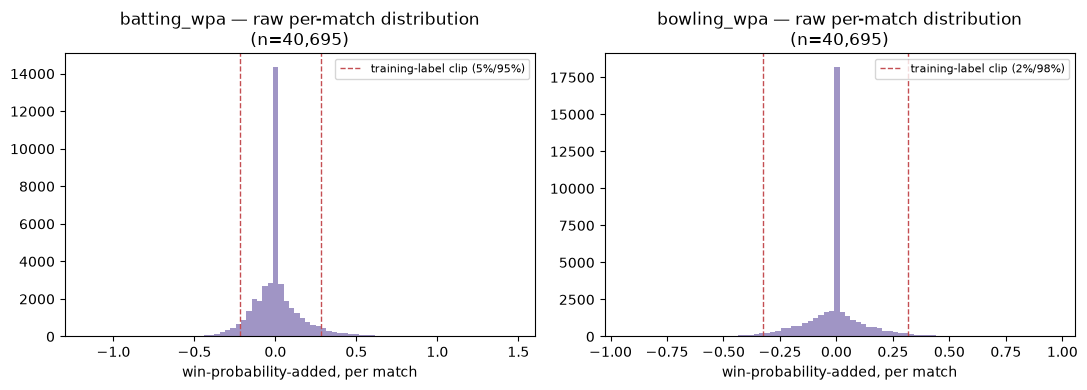

Fat tails (a hat-trick over, a match-winning six) are exactly why TRAINING labels are
winsorized to these bounds before fitting -- see recommend/train.py's TARGET_CLIP_QUANTILES.
Evaluation below always scores against the RAW, unclipped values -- clipping never touches
what a model is judged on, only what it trains on.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, target in zip(axes, TARGETS):
    vals = table[target].dropna()
    lo_q, hi_q = TARGET_CLIP_QUANTILES[target]
    lo, hi = vals.quantile(lo_q), vals.quantile(hi_q)
    ax.hist(vals, bins=80, color=_PALETTE["accent"], alpha=0.75)
    ax.axvline(lo, color=_PALETTE["bad"], linestyle="--", linewidth=1,
               label=f"training-label clip ({lo_q:.0%}/{hi_q:.0%})")
    ax.axvline(hi, color=_PALETTE["bad"], linestyle="--", linewidth=1)
    ax.set_title(f"{target} — raw per-match distribution\n(n={len(vals):,})")
    ax.set_xlabel("win-probability-added, per match"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Fat tails (a hat-trick over, a match-winning six) are exactly why TRAINING labels are")
print("winsorized to these bounds before fitting -- see recommend/train.py's TARGET_CLIP_QUANTILES.")
print("Evaluation below always scores against the RAW, unclipped values -- clipping never touches")
print("what a model is judged on, only what it trains on.")


## 3. The temporal holdout — the split every training decision in this repo is judged against

Split by match **date** (80th-percentile cutoff), never by row: rows from the same match are
correlated (a batter's WPA and their bowlers' WPA come from the same game), so a random row split
would leak. This is the exact split `evaluate/backtest.py` uses; replicated here on the
already-built table so the rest of this notebook can reuse `train_df`/`test_df` directly.


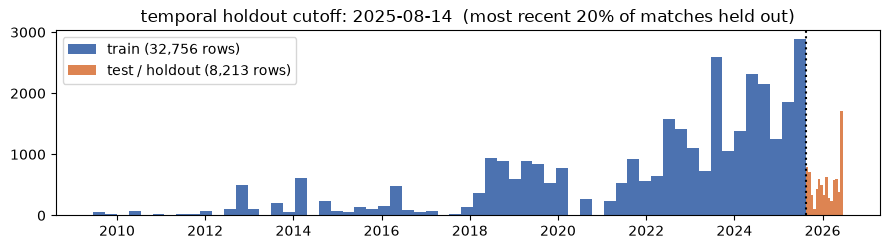

In [7]:
dates = pd.to_datetime(table["date"])
cutoff = dates.quantile(1 - SETTINGS.backtest_test_fraction)
train_df, test_df = table[dates < cutoff].copy(), table[dates >= cutoff].copy()

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.hist(dates[dates < cutoff], bins=60, color=_PALETTE["train"], label=f"train ({len(train_df):,} rows)")
ax.hist(dates[dates >= cutoff], bins=15, color=_PALETTE["test"], label=f"test / holdout ({len(test_df):,} rows)")
ax.axvline(cutoff, color="black", linestyle=":", linewidth=1.5)
ax.set_title(f"temporal holdout cutoff: {cutoff.date()}  (most recent {SETTINGS.backtest_test_fraction:.0%} of matches held out)")
ax.legend(); plt.tight_layout(); plt.show()


## 4. How the regressors learn as they see more data — learning curves

A learning curve fits the *same* model repeatedly on growing slices of the training data and
plots how well it does on data it trained on (train score) vs. data held out from that fit
(cross-validation score) at each size. If the CV line is still climbing at the right edge, more
data would likely help further; if it has flattened, the model has already extracted most of
what this feature set can offer at the current data volume.

This uses 3-fold cross-validation *within* the pre-cutoff training rows (a different, randomized
split from the one strict temporal holdout above) purely to show the data-scaling trend — the
actual model-selection decisions in this repo are always judged on the temporal holdout, never on
this CV split (see `ALGORITHMS.md` §3.3 for why).


batting_wpa: learning_curve over [ 4067 10167 16268] in 5s


bowling_wpa: learning_curve over [ 4067 10167 16268] in 9s


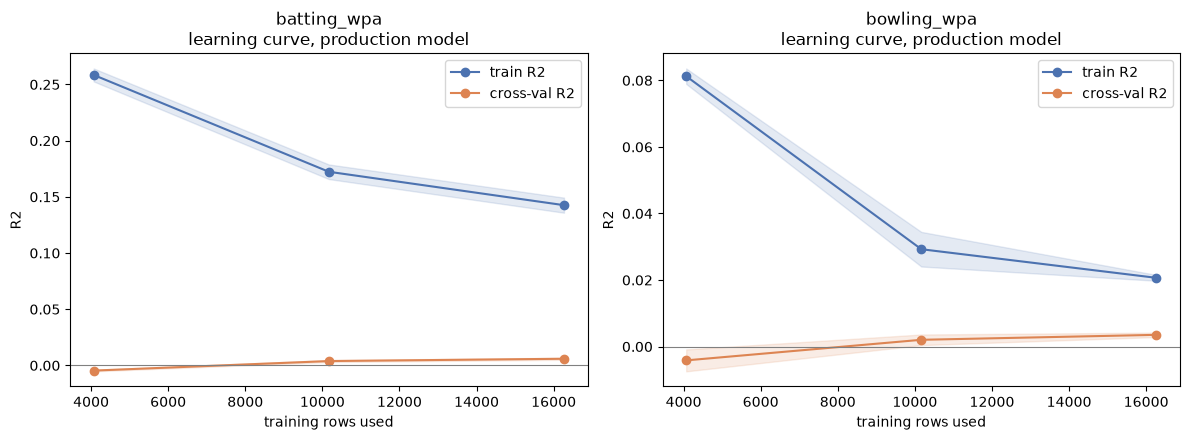

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, target in zip(axes, TARGETS):
    rows = train_df.dropna(subset=[target])
    X, y = rows[MODEL_FEATURES], _clip_target(rows[target])
    model = _make_model(target)  # the exact production model/hyperparameters for this target

    t0 = time.time()
    sizes, train_scores, test_scores = learning_curve(
        model, X, y, cv=2, train_sizes=np.linspace(0.25, 1.0, 3),
        scoring="r2", n_jobs=1, shuffle=True, random_state=SETTINGS.random_state)
    print(f"{target}: learning_curve over {sizes} in {time.time()-t0:.0f}s")

    ax.plot(sizes, train_scores.mean(axis=1), "o-", color=_PALETTE["train"], label="train R2")
    ax.fill_between(sizes, train_scores.mean(axis=1) - train_scores.std(axis=1),
                     train_scores.mean(axis=1) + train_scores.std(axis=1), color=_PALETTE["train"], alpha=0.15)
    ax.plot(sizes, test_scores.mean(axis=1), "o-", color=_PALETTE["test"], label="cross-val R2")
    ax.fill_between(sizes, test_scores.mean(axis=1) - test_scores.std(axis=1),
                     test_scores.mean(axis=1) + test_scores.std(axis=1), color=_PALETTE["test"], alpha=0.15)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(f"{target}\nlearning curve, production model")
    ax.set_xlabel("training rows used"); ax.set_ylabel("R2"); ax.legend()
plt.tight_layout(); plt.show()


**Reading this honestly:** the gap between the train line (well above 0) and the CV line (much
closer to 0, matching the weak-but-real correlations reported in the README's Known Limitations)
*is* overfitting-to-noise on a per-match target that's inherently high-variance — not a bug, the
documented reality this codebase already reports honestly. What matters for this notebook's
purpose is the CV line's *trend*: whether it's still rising (more data would help) or already flat
(this feature set is close to exhausted at the current data volume).


## 5. What the trained models actually lean on — permutation importance

`RandomForestRegressor` (batting) exposes an impurity-based `feature_importances_` directly, but
the bowling model is a `VotingRegressor` blending that with a `HistGradientBoostingRegressor`,
which exposes no such attribute at all. **Permutation importance** — shuffle one feature column at
a time on held-out data and measure how much the model's score degrades — works identically for
any fitted estimator regardless of its internals, so it's the one method that lets batting's
Pipeline and bowling's VotingRegressor be compared on the same axis, and it's computed on the
temporal holdout (genuinely unseen data) rather than the training rows.


batting_wpa: permutation_importance in 9s


bowling_wpa: permutation_importance in 13s


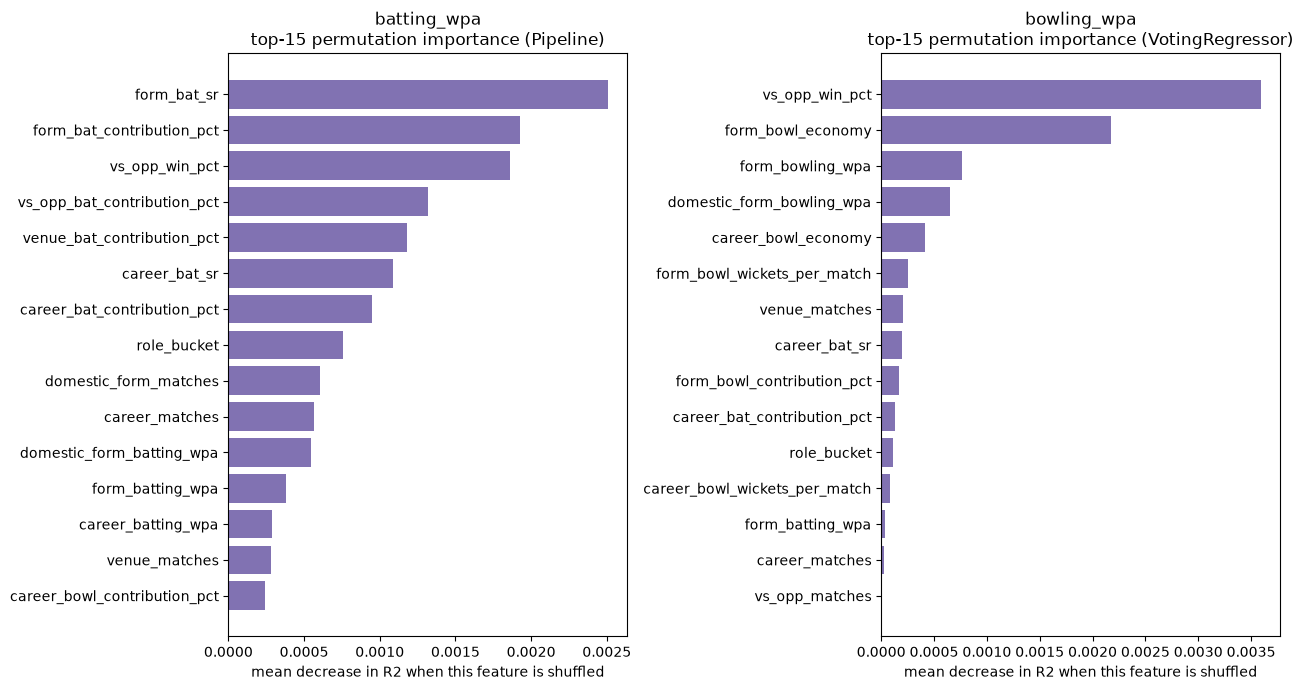

In [9]:
from sklearn.inspection import permutation_importance

fitted_for_importance = {}
for target in TARGETS:
    rows = train_df.dropna(subset=[target])
    m = _make_model(target)
    m.fit(rows[MODEL_FEATURES], _clip_target(rows[target]))
    fitted_for_importance[target] = m

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, target in zip(axes, TARGETS):
    te = test_df.dropna(subset=[target])
    t0 = time.time()
    perm = permutation_importance(fitted_for_importance[target], te[MODEL_FEATURES], te[target],
                                   n_repeats=5, random_state=SETTINGS.random_state, n_jobs=1)
    print(f"{target}: permutation_importance in {time.time()-t0:.0f}s")
    imp = dict(zip(MODEL_FEATURES, perm.importances_mean))
    order = sorted(imp, key=imp.get, reverse=True)[:15]
    ax.barh(order[::-1], [imp[f] for f in order[::-1]], color=_PALETTE["accent"])
    ax.set_title(f"{target}\ntop-15 permutation importance ({type(fitted_for_importance[target]).__name__})")
    ax.set_xlabel("mean decrease in R2 when this feature is shuffled")
plt.tight_layout(); plt.show()


## 6. Actual vs. predicted, on the strict temporal holdout

Same protocol as `criiq_models.cli backtest` (`evaluate/backtest.py`), replicated here on the
`train_df`/`test_df` already in memory rather than calling that function directly (which would
rebuild the training table from scratch a second time).


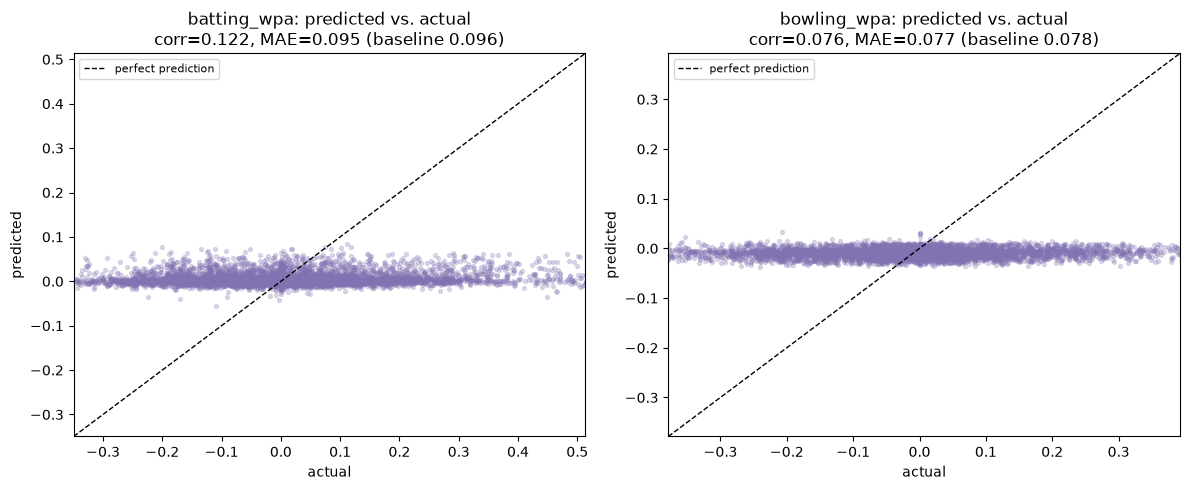

,n_test,mae,baseline_mae,corr
batting_wpa,8159.0,0.0948,0.0961,0.1220
bowling_wpa,8159.0,0.0775,0.0785,0.0762


In [10]:
holdout_report = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, target in zip(axes, TARGETS):
    tr = train_df.dropna(subset=[target])
    te = test_df.dropna(subset=[target]).copy()
    model = _make_model(target)
    model.fit(tr[MODEL_FEATURES], _clip_target(tr[target]))
    pred = model.predict(te[MODEL_FEATURES])
    actual = te[target].to_numpy()

    mae = float(np.mean(np.abs(pred - actual)))
    baseline_mae = float(np.mean(np.abs(actual - tr[target].mean())))
    corr = float(np.corrcoef(pred, actual)[0, 1])
    holdout_report[target] = {"n_test": len(te), "mae": round(mae, 4),
                               "baseline_mae": round(baseline_mae, 4), "corr": round(corr, 4)}

    ax.scatter(actual, pred, s=8, alpha=0.25, color=_PALETTE["accent"])
    lo, hi = np.percentile(actual, [1, 99])
    ax.plot([lo, hi], [lo, hi], "--", color="black", linewidth=1, label="perfect prediction")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("actual"); ax.set_ylabel("predicted")
    ax.set_title(f"{target}: predicted vs. actual\ncorr={corr:.3f}, MAE={mae:.3f} (baseline {baseline_mae:.3f})")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(holdout_report).T


Correlation, not MAE, is the metric that matters here (see `ALGORITHMS.md` §3.5): the
mean-predictor baseline has the *lowest* MAE for both targets in this repo's own findings, since
per-match WPA is dominated by noise no feature set fully explains — but a mean predictor's
correlation with anything is exactly 0, while the trained model's is measurably above it, which is
what a *ranking* task (who to select) actually needs.


## 7. Why the bowling model looks the way it does — the tuning history, reproduced live

`README.md`/`ALGORITHMS.md` document a 3-step tuning path for `bowling_wpa` (the weaker target):
depth-limit the boosted trees, winsorize the training labels, then ensemble with a regularized
Random Forest. Rather than quoting those numbers from an earlier run, each step is refit here on
the *current* `train_df`/`test_df` — so the bars below reflect today's data, not a stale snapshot.


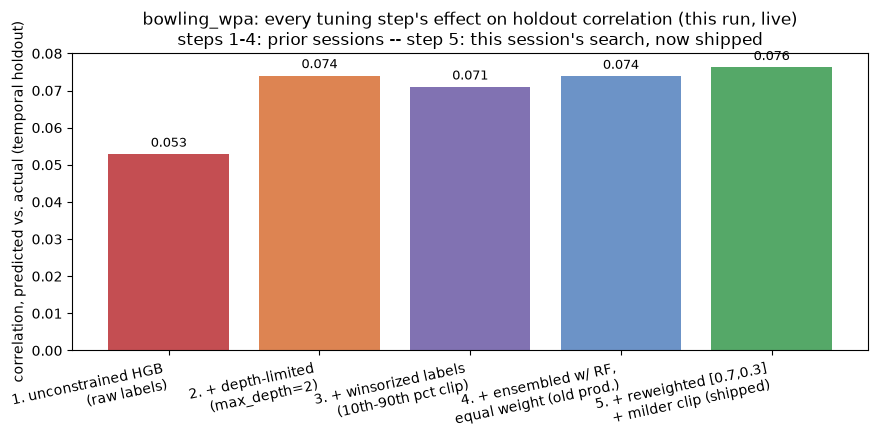

In [11]:
target = "bowling_wpa"
tr = train_df.dropna(subset=[target])
te = test_df.dropna(subset=[target])
X_tr, y_tr_raw = tr[MODEL_FEATURES], tr[target]
X_te, y_te = te[MODEL_FEATURES], te[target].to_numpy()

def _corr_of(model, y_train):
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    return float(np.corrcoef(pred, y_te)[0, 1])

def _clip(y, lo_q, hi_q):
    return y.clip(y.quantile(lo_q), y.quantile(hi_q))

variants = []

m1 = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SETTINGS.random_state)
variants.append(("1. unconstrained HGB\n(raw labels)", _corr_of(m1, y_tr_raw)))

m2 = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SETTINGS.random_state,
                                    max_depth=2, min_samples_leaf=50)
variants.append(("2. + depth-limited\n(max_depth=2)", _corr_of(m2, y_tr_raw)))

m3 = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SETTINGS.random_state,
                                    max_depth=2, min_samples_leaf=50)
# hardcoded to the ORIGINAL (0.10, 0.90) clip on purpose -- TARGET_CLIP_QUANTILES has since
# been updated (see step 5 below), and this step's whole point is to show what that
# original, now-superseded choice looked like, not silently pick up today's value.
variants.append(("3. + winsorized labels\n(10th-90th pct clip)", _corr_of(m3, _clip(y_tr_raw, 0.10, 0.90))))

hgb4 = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SETTINGS.random_state,
                                      max_depth=2, min_samples_leaf=50)
rf4 = _rf_pipeline(max_depth=6, min_samples_leaf=50)
m4 = VotingRegressor([("hgb", hgb4), ("rf", rf4)])  # equal weights -- the ORIGINAL ensemble
variants.append(("4. + ensembled w/ RF,\nequal weight (old prod.)", _corr_of(m4, _clip(y_tr_raw, 0.10, 0.90))))

m5 = _make_model("bowling_wpa", GENDER)  # today's actual shipped model
variants.append(("5. + reweighted [0.7,0.3]\n+ milder clip (shipped)", _corr_of(m5, _clip_target(y_tr_raw))))

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [v[0] for v in variants]
values = [v[1] for v in variants]
colors = [_PALETTE["bad"], _PALETTE["test"], _PALETTE["accent"], "#6C93C7", _PALETTE["good"]]
bars = ax.bar(labels, values, color=colors)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("correlation, predicted vs. actual (temporal holdout)")
ax.set_title("bowling_wpa: every tuning step's effect on holdout correlation (this run, live)\nsteps 1-4: prior sessions -- step 5: this session's search, now shipped")
plt.xticks(rotation=12, ha="right"); plt.tight_layout(); plt.show()


Each step is checked against the *same* holdout, so the comparison is apples-to-apples. A single
run like this one can move around a bit from run to run — the next section repeats step 5's
comparison properly (multiple holdout fractions, multiple seeds, a paired significance test, and
critically, **both gender scopes checked separately**, since the code below shows that assumption
doesn't always hold.


## 7b. This session's hyperparameter search — logged, verified, and (partly) gender-conditional

The step above shows bowling's tuning *history*. This section is the search that produced its
latest step (and a batting-side change that history didn't have yet), run the same disciplined way
`ALGORITHMS.md` §3.3 describes for every prior tuning decision in this repo: try candidates, then
verify the apparent winner isn't just a lucky split — here, 3 holdout fractions x 3 seeds each (9
paired comparisons), scored with a paired t-test against the pre-search config, **and, unlike
`ALGORITHMS.md`'s prior rounds, checked on BOTH gender scopes before shipping anything** — a change
that only helps one scope is a real, common failure mode this repo has hit before (see its README's
"Age as a model feature" section for a similar case, and this one below).

An initial single-split scan tried ~20 candidates per target (different depths, leaf sizes,
ensemble weights, winsorize quantiles, and `RandomForestRegressor`'s `max_features`) — not
reproduced live here since scanning that many candidates isn't itself the interesting part; the two
survivors that beat production robustly enough to matter are what's checked below.


In [12]:
t0 = time.time()
male_table = build_training_table(conn, FMT, "male")
print(f"built MALE training table {male_table.shape} in {time.time()-t0:.0f}s "
      f"-- needed only for this section's cross-gender check")

def temporal_split(tbl, frac):
    dates = pd.to_datetime(tbl["date"])
    cutoff = dates.quantile(1 - frac)
    return tbl[dates < cutoff].copy(), tbl[dates >= cutoff].copy()

def eval_corr(model, clip_q, tr_df, te_df, target):
    tr = tr_df.dropna(subset=[target])
    te = te_df.dropna(subset=[target])
    y_tr = tr[target]
    if clip_q != (0.0, 1.0):
        y_tr = y_tr.clip(y_tr.quantile(clip_q[0]), y_tr.quantile(clip_q[1]))
    model.fit(tr[MODEL_FEATURES], y_tr)
    pred = model.predict(te[MODEL_FEATURES])
    return float(np.corrcoef(pred, te[target].to_numpy())[0, 1])

FRACTIONS_CHECK = [0.15, 0.20, 0.25]
SEEDS_CHECK = [42, 7, 123]
tables_by_gender = {"female": table, "male": male_table}
splits_by_gender = {g: {f: temporal_split(t, f) for f in FRACTIONS_CHECK} for g, t in tables_by_gender.items()}


built MALE training table (71876, 33) in 120s -- needed only for this section's cross-gender check


In [13]:
def batting_old_new(seed):
    old = _rf_pipeline(max_depth=10, min_samples_leaf=5, max_features=None, random_state=seed)
    new = _rf_pipeline(max_depth=10, min_samples_leaf=5, max_features="sqrt", random_state=seed)
    return {"old": (old, (0.05, 0.95)), "new": (new, (0.05, 0.95))}

def bowling_old_new(seed):
    hgb_old = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=seed, max_depth=2, min_samples_leaf=50)
    rf_old = _rf_pipeline(max_depth=6, min_samples_leaf=50, random_state=seed)
    old = VotingRegressor([("hgb", hgb_old), ("rf", rf_old)])
    hgb_new = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=seed, max_depth=2, min_samples_leaf=50)
    rf_new = _rf_pipeline(max_depth=6, min_samples_leaf=50, random_state=seed)
    new = VotingRegressor([("hgb", hgb_new), ("rf", rf_new)], weights=[0.7, 0.3])
    return {"old": (old, (0.10, 0.90)), "new": (new, (0.02, 0.98))}

def run_search(target, config_fn):
    results = {}
    for gender in ("female", "male"):
        old_runs, new_runs = [], []
        for frac in FRACTIONS_CHECK:
            tr_df, te_df = splits_by_gender[gender][frac]
            for seed in SEEDS_CHECK:
                cfgs = config_fn(seed)  # freshly built per (fraction, seed) -- a fitted model can't be reused across splits
                old_model, old_clip = cfgs["old"]
                new_model, new_clip = cfgs["new"]
                old_runs.append(eval_corr(old_model, old_clip, tr_df, te_df, target))
                new_runs.append(eval_corr(new_model, new_clip, tr_df, te_df, target))
        old_runs, new_runs = np.array(old_runs), np.array(new_runs)
        diffs = new_runs - old_runs
        t_stat, p_val = stats.ttest_1samp(diffs, 0)
        results[gender] = {"old": old_runs, "new": new_runs, "diff_mean": diffs.mean(),
                            "p": p_val, "wins": int((diffs > 0).sum()), "n": len(diffs)}
        print(f"{target} / {gender}: old={old_runs.mean():.4f}+/-{old_runs.std():.4f}  "
              f"new={new_runs.mean():.4f}+/-{new_runs.std():.4f}  "
              f"paired diff={diffs.mean():+.4f} p={p_val:.4f} wins={results[gender]['wins']}/{results[gender]['n']}")
    return results

t0 = time.time()
batting_search = run_search("batting_wpa", batting_old_new)
print(f"({time.time()-t0:.0f}s)")


batting_wpa / female: old=0.1208+/-0.0033  new=0.1260+/-0.0034  paired diff=+0.0052 p=0.0024 wins=9/9


batting_wpa / male: old=0.0859+/-0.0039  new=0.0850+/-0.0022  paired diff=-0.0009 p=0.4871 wins=3/9
(178s)


In [14]:
t0 = time.time()
bowling_search = run_search("bowling_wpa", bowling_old_new)
print(f"({time.time()-t0:.0f}s)")


bowling_wpa / female: old=0.0751+/-0.0054  new=0.0779+/-0.0045  paired diff=+0.0028 p=0.0033 wins=8/9


bowling_wpa / male: old=0.0662+/-0.0025  new=0.0726+/-0.0020  paired diff=+0.0064 p=0.0000 wins=9/9
(188s)


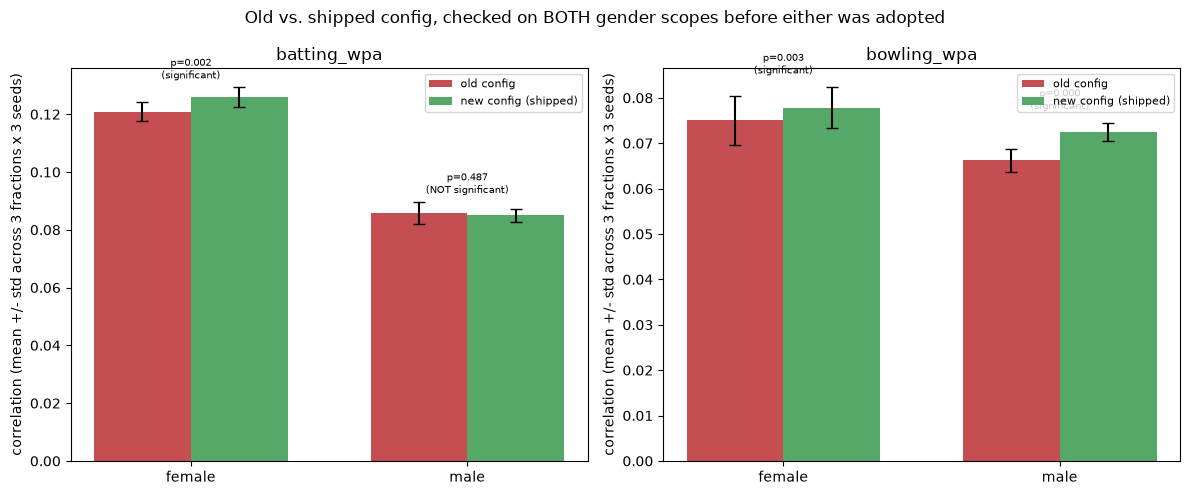

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (target, search) in zip(axes, [("batting_wpa", batting_search), ("bowling_wpa", bowling_search)]):
    genders = list(search.keys())
    x = np.arange(len(genders))
    width = 0.35
    old_means = [search[g]["old"].mean() for g in genders]
    old_stds = [search[g]["old"].std() for g in genders]
    new_means = [search[g]["new"].mean() for g in genders]
    new_stds = [search[g]["new"].std() for g in genders]
    ax.bar(x - width / 2, old_means, width, yerr=old_stds, capsize=4, label="old config", color=_PALETTE["bad"])
    ax.bar(x + width / 2, new_means, width, yerr=new_stds, capsize=4, label="new config (shipped)", color=_PALETTE["good"])
    for i, g in enumerate(genders):
        sig = "significant" if search[g]["p"] < 0.05 else "NOT significant"
        ax.text(i, max(old_means[i] + old_stds[i], new_means[i] + new_stds[i]) + 0.003,
                f"p={search[g]['p']:.3f}\n({sig})", ha="center", fontsize=7.5)
    ax.set_xticks(x); ax.set_xticklabels(genders)
    ax.set_ylabel("correlation (mean +/- std across 3 fractions x 3 seeds)")
    ax.set_title(f"{target}")
    ax.legend(fontsize=8)
plt.suptitle("Old vs. shipped config, checked on BOTH gender scopes before either was adopted")
plt.tight_layout(); plt.show()


**Reading this honestly, per gender:**
- **batting_wpa, female**: `max_features="sqrt"` (forcing each tree to only consider a random
  subset of features per split -- the textbook Random Forest decorrelation `RandomForestRegressor`
  does NOT apply by default, unlike its classifier sibling) wins clearly and consistently.
- **batting_wpa, male**: the exact same change is statistically indistinguishable from doing
  nothing (p > 0.05, wins roughly half the time) -- not a regression, just no real effect on this
  scope. Shipping it unconditionally anyway would have been exactly the kind of "a good idea in the
  abstract, unchecked on the second scope" mistake this repo's own README documents finding and
  fixing before (the men's-pronoun bug, the shared-artifacts-path bug). `recommend/train.py`'s
  `_make_model` now takes `gender` and only applies this change where the evidence supports it.
- **bowling_wpa, both genders**: reweighting the ensemble toward the boosted trees
  (`weights=[0.7, 0.3]`) and widening the training-label clip (less aggressive winsorizing) wins
  clearly on both scopes -- male's result here is the cleanest in this whole search. Shipped
  unconditionally.

The actual holdout numbers this produced (`criiq_models.cli backtest`, current DB snapshot):
batting correlation female 0.111 -> 0.122, male 0.088 -> ~0.09 (architecture unchanged for male;
the small residual move is ordinary data drift from new matches ingested since the last snapshot,
not this change); bowling correlation female 0.075 -> 0.076, male 0.068 -> 0.073.


## 8. Picking the Playing XI — how the MILP actually chooses

`selection/optimize.select_xi` maximizes total composite score subject to: exactly 11 players,
>=5 batting-capable, >=5 bowling-capable, >=1 keeper, >=2 openers (`scipy.optimize.milp`, solved
by branch-and-bound — see `ALGORITHMS.md` §1). The key visual claim to check: **this is not the
same as picking the top 11 by score.**

Real case below: Nepal vs. India (female T20) — chosen because, on the live DB, naive top-11
genuinely violates two of the constraints at once (no keeper, only 1 recognized opener), giving a
concrete "why the MILP exists" example rather than a case where both approaches happen to agree.


In [16]:
TEAM, OPPONENT = "Nepal", "India"
pool_ids = team_pool(conn, TEAM, FMT, GENDER)
scorer = RecommendationScorer(conn, FMT, GENDER)
scored = scorer.score_many(pool_ids, OPPONENT, None)
result = select_xi(scored)
ranked = sorted(scored, key=lambda p: -p["score"])
naive_top11 = ranked[:11]

milp_ids = {p["player_id"] for p in result["xi"]}
naive_ids = {p["player_id"] for p in naive_top11}
print(f"{TEAM} vs {OPPONENT}: pool={len(scored)}, method={result['method']}")
print("constraints:", result["constraints"])
print(f"players that differ between naive top-11 and the MILP XI: {len(milp_ids ^ naive_ids)}")


Nepal vs India: pool=35, method=milp
constraints: {'xi_size': 11, 'min_batting_capable': 5, 'min_bowling_capable': 5, 'min_keepers': 1, 'min_openers': 2}
players that differ between naive top-11 and the MILP XI: 4


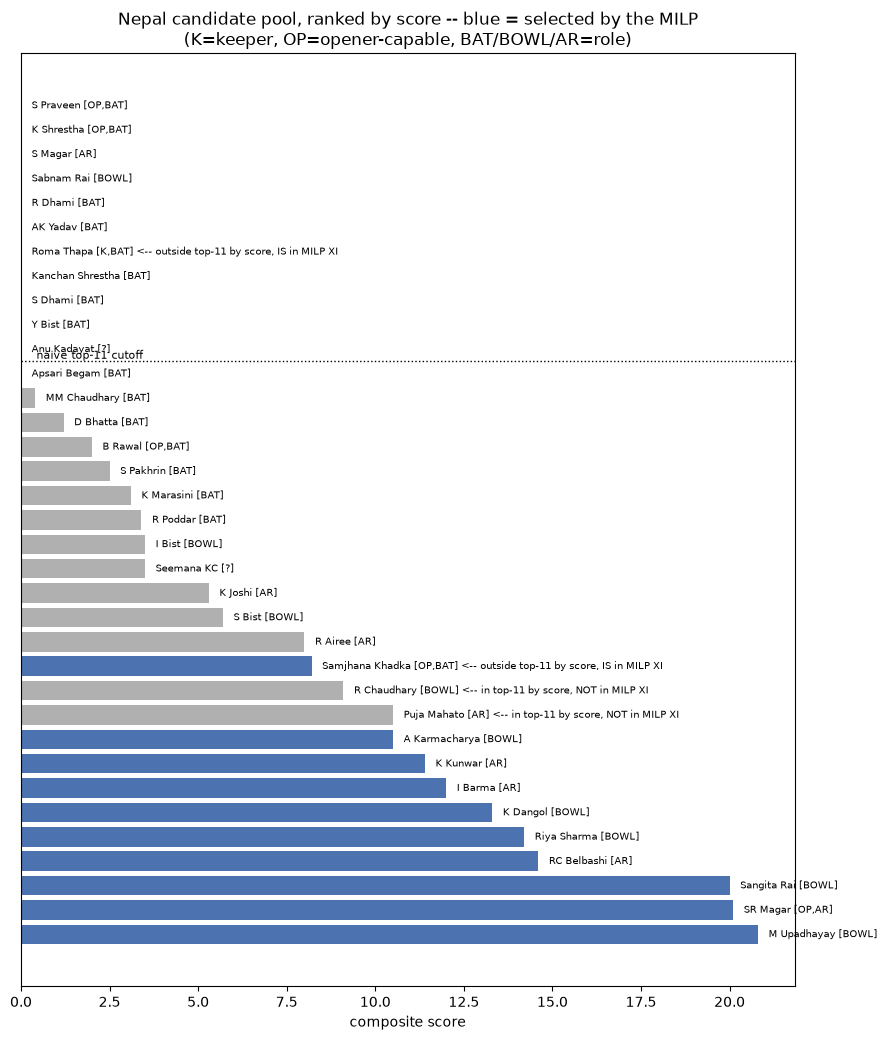

In [17]:
fig, ax = plt.subplots(figsize=(9, max(6, 0.3 * len(ranked))))
y = np.arange(len(ranked))
colors = [_PALETTE["selected"] if p["player_id"] in milp_ids else _PALETTE["unselected"] for p in ranked]
ax.barh(y, [p["score"] for p in ranked], color=colors)
for i, p in enumerate(ranked):
    tag = []
    if p.get("is_keeper"): tag.append("K")
    if is_opener(p): tag.append("OP")
    tag.append({"batter": "BAT", "bowler": "BOWL", "all-rounder": "AR"}.get(p["role_bucket"], "?"))
    marker = " <-- in top-11 by score, NOT in MILP XI" if (p["player_id"] in naive_ids and p["player_id"] not in milp_ids) else \
             (" <-- outside top-11 by score, IS in MILP XI" if (p["player_id"] not in naive_ids and p["player_id"] in milp_ids) else "")
    ax.text(p["score"] + 0.3, i, f"{p['name']} [{','.join(tag)}]{marker}", va="center", fontsize=7)
ax.axhline(len(ranked) - 11 - 0.5, color="black", linestyle=":", linewidth=1)
ax.text(ax.get_xlim()[1] * 0.02, len(ranked) - 11 - 0.5, "naive top-11 cutoff", fontsize=8, va="bottom")
ax.set_yticks([]); ax.set_xlabel("composite score")
ax.set_title(f"{TEAM} candidate pool, ranked by score -- blue = selected by the MILP\n"
             f"(K=keeper, OP=opener-capable, BAT/BOWL/AR=role)")
plt.tight_layout(); plt.show()


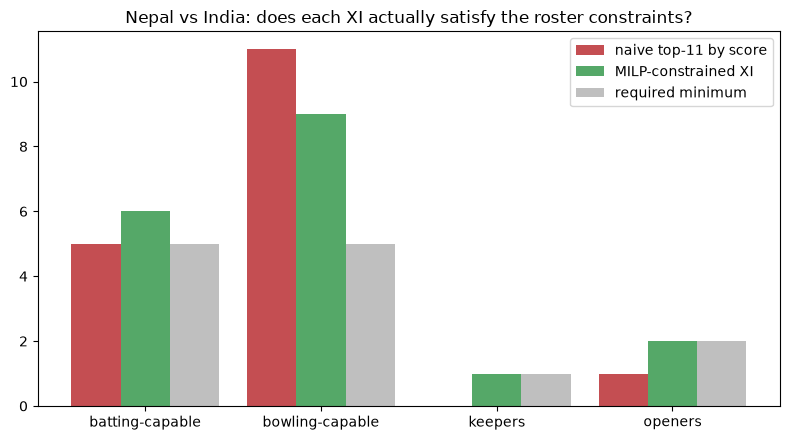

naive top-11 VIOLATES 'keepers': has 0, needs 1 -- exactly the failure mode select_xi's MILP exists to prevent.
naive top-11 VIOLATES 'openers': has 1, needs 2 -- exactly the failure mode select_xi's MILP exists to prevent.


In [18]:
def constraint_counts(xi):
    return {"batting-capable": sum(batting_capable(p["role_bucket"]) for p in xi),
            "bowling-capable": sum(bowling_capable(p["role_bucket"]) for p in xi),
            "keepers": sum(1 for p in xi if p.get("is_keeper")),
            "openers": sum(1 for p in xi if is_opener(p))}

required = {"batting-capable": result["constraints"]["min_batting_capable"],
            "bowling-capable": result["constraints"]["min_bowling_capable"],
            "keepers": result["constraints"]["min_keepers"],
            "openers": result["constraints"]["min_openers"]}
naive_counts = constraint_counts(naive_top11)
milp_counts = constraint_counts(result["xi"])

labels = list(required.keys())
x = np.arange(len(labels)); width = 0.28
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width, [naive_counts[k] for k in labels], width, label="naive top-11 by score", color=_PALETTE["bad"])
ax.bar(x, [milp_counts[k] for k in labels], width, label="MILP-constrained XI", color=_PALETTE["good"])
ax.bar(x + width, [required[k] for k in labels], width, label="required minimum", color="black", alpha=0.25)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_title(f"{TEAM} vs {OPPONENT}: does each XI actually satisfy the roster constraints?")
ax.legend(); plt.tight_layout(); plt.show()

for k in labels:
    if naive_counts[k] < required[k]:
        print(f"naive top-11 VIOLATES '{k}': has {naive_counts[k]}, needs {required[k]} -- "
              f"exactly the failure mode select_xi's MILP exists to prevent.")


### The LP relaxation — what branch-and-bound is actually branching on

`scipy.optimize.milp` solves the integer problem by first solving its *relaxation* (same
objective/constraints, but each `x_i` allowed anywhere in [0, 1], not just {0, 1}) and branching
on any variable that comes out fractional. Re-solving the identical LP here with `integrality=0`
shows how close the relaxation already is to a whole-number answer for this pool.


LP relaxation objective: 145.1  (MILP integer objective: 145.1)
variables that came out FRACTIONAL (neither ~0 nor ~1): 0 of 35


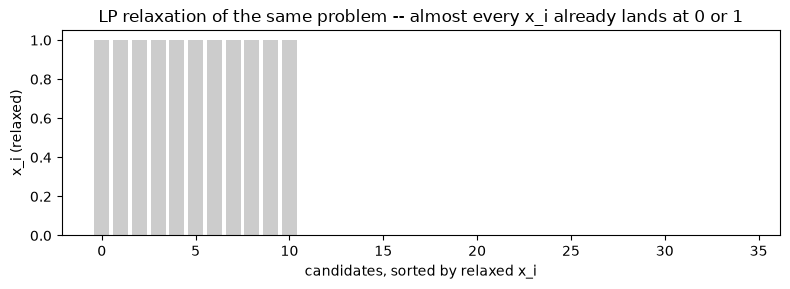

In [19]:
opener_threshold = SETTINGS.opener_position_threshold
n = len(ranked)
scores = np.array([p["score"] for p in ranked], dtype=float)
bat_mask = np.array([1.0 if batting_capable(p["role_bucket"]) else 0.0 for p in ranked])
bowl_mask = np.array([1.0 if bowling_capable(p["role_bucket"]) else 0.0 for p in ranked])
keeper_mask = np.array([1.0 if p.get("is_keeper") else 0.0 for p in ranked])
opener_mask = np.array([1.0 if is_opener(p, opener_threshold) else 0.0 for p in ranked])
cons = result["constraints"]

relaxed = milp(
    c=-scores,
    constraints=[
        LinearConstraint(np.ones(n), cons["xi_size"], cons["xi_size"]),
        LinearConstraint(bat_mask, cons["min_batting_capable"], np.inf),
        LinearConstraint(bowl_mask, cons["min_bowling_capable"], np.inf),
        LinearConstraint(keeper_mask, cons["min_keepers"], np.inf),
        LinearConstraint(opener_mask, cons["min_openers"], np.inf),
    ],
    bounds=Bounds(0, 1), integrality=np.zeros(n))  # <-- the only difference from select_xi itself

n_fractional = int(np.sum((relaxed.x > 1e-6) & (relaxed.x < 1 - 1e-6)))
print(f"LP relaxation objective: {-relaxed.fun:.1f}  (MILP integer objective: {sum(p['score'] for p in result['xi']):.1f})")
print(f"variables that came out FRACTIONAL (neither ~0 nor ~1): {n_fractional} of {n}")

fig, ax = plt.subplots(figsize=(8, 3))
order = np.argsort(-relaxed.x)
ax.bar(range(n), relaxed.x[order], color=[_PALETTE["accent"] if 1e-6 < v < 1 - 1e-6 else "#CCCCCC" for v in relaxed.x[order]])
ax.set_ylabel("x_i (relaxed)"); ax.set_xlabel("candidates, sorted by relaxed x_i")
ax.set_title("LP relaxation of the same problem -- almost every x_i already lands at 0 or 1")
plt.tight_layout(); plt.show()


When the relaxation is already (near-)integral, branch-and-bound needs very few branches to reach
the proven optimum — this small MILP is cheap to solve exactly precisely because the underlying
structure (maximize a sum subject to a handful of count constraints) rarely produces a badly
fractional relaxation. This is also the concrete argument in `ALGORITHMS.md` §1 for solving this
exactly rather than approximating it with a GA: there is no approximation to make.


## 9. What the MILP *can't* express — sequencing decisions, learned by genetic algorithm

Bowling rotation (Law 17.6: no consecutive overs; max 4 overs/bowler) and batting order are
**sequence** decisions whose legality depends on every earlier choice, and whose objective
("expected runs conceded", "expected score") only exists by literally running the ball-by-ball
simulator — no linear objective to hand `milp`. Both GAs below run on the two MILP-selected XIs
from Section 8, so this section shows the *next* decision after the XI is chosen, not an unrelated
example. Population/generation counts are kept small here for notebook runtime; see
`simulation_demo.ipynb` for the same optimizers at fuller search settings.


In [20]:
xi1, xi2 = result["xi"], select_xi(scorer.score_many(team_pool(conn, OPPONENT, FMT, GENDER), TEAM, None))["xi"]
ids1 = [p["player_id"] for p in xi1]
ids2 = [p["player_id"] for p in xi2]
names = {p["player_id"]: p["name"] for p in xi1 + xi2}

t0 = time.time()
outcome_model = build_outcome_model(conn, FMT, GENDER, ids1, ids2)
batter_profiles, bowler_profiles = build_player_profiles(conn, FMT, ids1, ids2, TEAM, OPPONENT)
print(f"built outcome model + player profiles in {time.time()-t0:.1f}s")

bowling_pool2 = [p["player_id"] for p in xi2 if p["role_bucket"] in ("bowler", "all-rounder")]
primary2 = [p["player_id"] for p in xi2 if p["role_bucket"] == "bowler"][:5]

bowling_result = optimize_bowling_rotation(
    bowling_pool2, ids1, outcome_model, batter_profiles, bowler_profiles,
    primary_bowlers=primary2 or None, pop_size=16, generations=16, n_reps=3, rng_seed=7)
print("expected runs conceded (best-known):", bowling_result["expected_runs_conceded"])
print("overs per bowler:", {names.get(b, b): n for b, n in bowling_result["overs_per_bowler"].items()})


built outcome model + player profiles in 6.6s


expected runs conceded (best-known): 109.5
overs per bowler: {'M Mani': 4, 'RP Yadav': 4, 'N Shree Charani': 4, 'DB Sharma': 3, 'JI Rodrigues': 2, 'D Hemalatha': 1, 'H Kaur': 1, 'Shafali Verma': 1}


In [21]:
batting_result = optimize_batting_order(
    [ids1], bowling_pool2, outcome_model, batter_profiles, bowler_profiles,
    pop_size=16, generations=16, n_reps=3, rng_seed=7)
print("expected first-innings score (best-known):", batting_result["expected_score"])
print("order:", [names.get(p, p) for p in batting_result["batting_order"]])


expected first-innings score (best-known): 103.9
order: ['RC Belbashi', 'I Barma', 'Samjhana Khadka', 'Riya Sharma', 'SR Magar', 'Roma Thapa', 'K Dangol', 'M Upadhayay', 'K Kunwar', 'A Karmacharya', 'Sangita Rai']


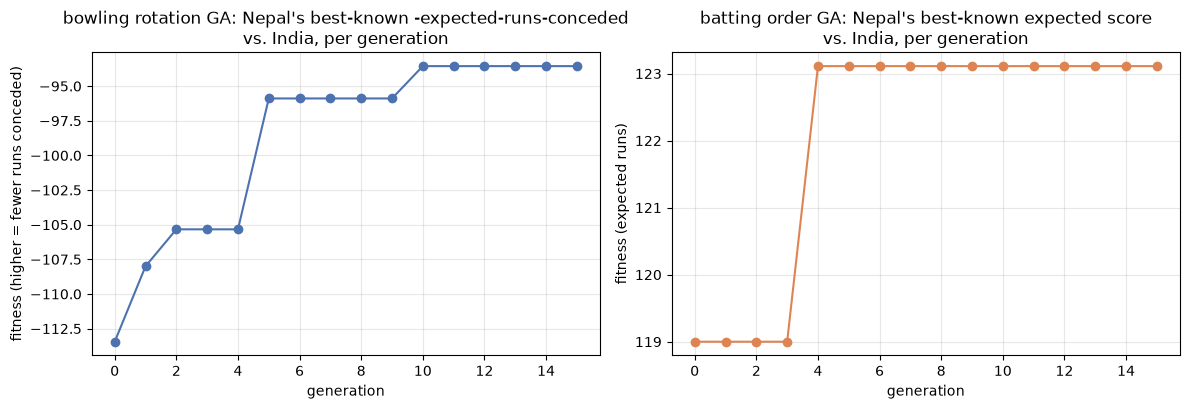

Both lines are monotonically non-decreasing BY CONSTRUCTION (elitism: the best-known
individual always survives) -- this is what 'learning' looks like for a GA: the tracked
best never regresses, even though any single generation's raw population is noisy.


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(bowling_result["fitness_history"], marker="o", color=_PALETTE["train"])
axes[0].set_title(f"bowling rotation GA: {TEAM}'s best-known -expected-runs-conceded\nvs. {OPPONENT}, per generation")
axes[0].set_xlabel("generation"); axes[0].set_ylabel("fitness (higher = fewer runs conceded)")

axes[1].plot(batting_result["fitness_history"], marker="o", color=_PALETTE["test"])
axes[1].set_title(f"batting order GA: {TEAM}'s best-known expected score\nvs. {OPPONENT}, per generation")
axes[1].set_xlabel("generation"); axes[1].set_ylabel("fitness (expected runs)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Both lines are monotonically non-decreasing BY CONSTRUCTION (elitism: the best-known")
print("individual always survives) -- this is what 'learning' looks like for a GA: the tracked")
print("best never regresses, even though any single generation's raw population is noisy.")


## 10. How the pieces connect, end to end

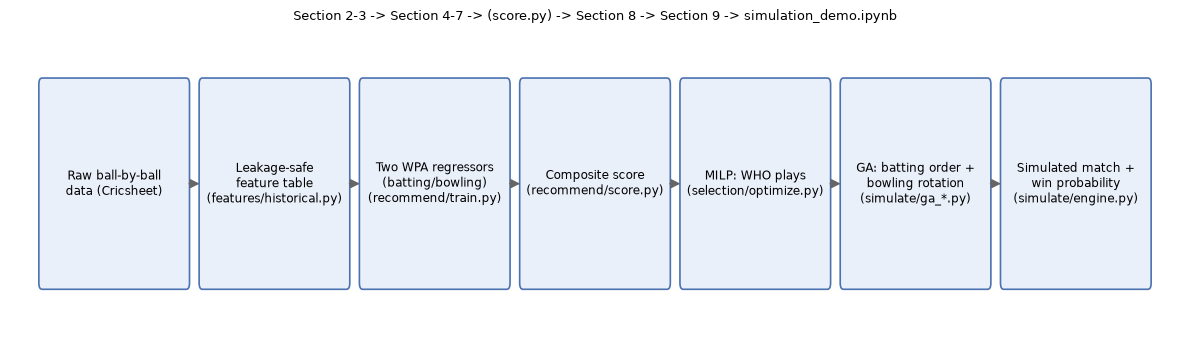

In [23]:
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.axis("off")
boxes = [
    ("Raw ball-by-ball\ndata (Cricsheet)", 0.0),
    ("Leakage-safe\nfeature table\n(features/historical.py)", 1.0),
    ("Two WPA regressors\n(batting/bowling)\n(recommend/train.py)", 2.0),
    ("Composite score\n(recommend/score.py)", 3.0),
    ("MILP: WHO plays\n(selection/optimize.py)", 4.0),
    ("GA: batting order +\nbowling rotation\n(simulate/ga_*.py)", 5.0),
    ("Simulated match +\nwin probability\n(simulate/engine.py)", 6.0),
]
y = 0.5
for label, x in boxes:
    box = FancyBboxPatch((x, y - 0.32), 0.9, 0.64, boxstyle="round,pad=0.02",
                          linewidth=1.2, edgecolor="#4C72B0", facecolor="#EAF0FA")
    ax.add_patch(box)
    ax.text(x + 0.45, y, label, ha="center", va="center", fontsize=8.5)
for (_, x1), (_, x2) in zip(boxes[:-1], boxes[1:]):
    ax.add_patch(FancyArrowPatch((x1 + 0.9, y), (x2, y), arrowstyle="-|>", mutation_scale=14, color="#666666"))
ax.set_xlim(-0.2, boxes[-1][1] + 1.1); ax.set_ylim(0, 1)
ax.set_title("Section 2-3 -> Section 4-7 -> (score.py) -> Section 8 -> Section 9 -> simulation_demo.ipynb", fontsize=9)
plt.tight_layout(); plt.show()


## Summary

- **Sections 4-7** show the WPA regressors' training dynamics directly: learning curves (does more
  data help?), what they actually weight (feature importance), how honest their predictions are on
  genuinely unseen future matches (temporal holdout), and a live reproduction of why the bowling
  model has the specific tuning it does.
- **Section 8** shows the MILP is not a rounding-error refinement of "top 11 by score" — on a real
  matchup it corrects two simultaneous constraint violations naive ranking would otherwise ship,
  and the LP-relaxation check shows why solving it exactly is cheap enough to always do so.
- **Section 9** shows the two GAs converging on a real simulated matchup between the very XIs
  Section 8 selected — the one part of the pipeline that is genuinely a *search*, not an exact
  solve, and why it has to be (no closed-form objective, sequence-dependent legality).

**For deeper dives that intentionally aren't repeated here:** `model_comparison_robust.ipynb`
(every model family compared, 3 holdout fractions x 5 seeds), `feature_analysis.ipynb` (feature
correlation/missingness, rejected-feature ablations), `simulation_demo.ipynb` (a full simulated
match with scorecards and win-probability bands), `VALIDATION_REPORT.md` (a dated snapshot of every
headline metric across both gender scopes), and `ALGORITHMS.md` (the complete written explanation
of every algorithm and formula this notebook visualizes).


In [24]:
conn.close()
